# Renewable Energy Transition Across Countries
## Milestone 3: Visual drafts
These charts compare renewable energy adoption and selected renewable electricity pathways across ten countries in 2024. The target audience is university peers and readers interested in energy policy who need clear comparisons without specialist knowledge.

Total energy and electricity generation have different denominators; the two charts should be read separately. Source: Our World in Data Energy Dataset, using the project's cleaned CSV.

**Measure definitions.** Visual 1 uses the renewable share of **primary energy consumption**, calculated with the substitution method; it is not a share of final energy consumption. Visual 2 uses solar, wind, and hydro shares of **total electricity generation**. Their common electricity denominator makes them suitable for stacking, but their percentages must not be compared directly with Visual 1.

Definitions and attribution were checked against `data/energy_source/owid-energy-codebook.csv`. [Our World in Data Energy Dataset documentation](https://github.com/owid/energy-data) describes this legacy dataset; the project uses its saved source snapshot, rather than a live download.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Resolve paths from either the repository root or notebooks/ in VS Code.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/energy_10countries_clean.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from within the project repository.")
OUTPUT = ROOT / "visuals"
OUTPUT.mkdir(exist_ok=True)
YEAR = 2024
SHARES = ["renewables_share_energy", "solar_share_elec",
          "wind_share_elec", "hydro_share_elec"]
data = pd.read_csv(ROOT / "data/energy_10countries_clean.csv")
frame = (data.loc[data["year"].eq(YEAR), ["country", *SHARES]]
         .sort_values("renewables_share_energy", ascending=False)
         .reset_index(drop=True))
COUNTRIES = {"Brazil", "China", "Denmark", "France", "Germany", "India",
             "Japan", "Norway", "South Africa", "United States"}
assert len(frame) == 10 and set(frame["country"]) == COUNTRIES, "Unexpected country selection."
assert not data.duplicated(["country", "year"]).any(), "Duplicate country-year rows."
assert frame[SHARES].notna().all().all(), "Missing chart values."
assert frame[SHARES].ge(0).all().all() and frame[SHARES].le(100).all().all()
assert frame[SHARES[1:]].sum(axis=1).le(100.01).all()

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.spines.left": False, "axes.spines.bottom": False,
                     "axes.labelcolor": "#334155", "text.color": "#172B3A",
                     "xtick.color": "#526171", "ytick.color": "#172B3A",
                     "figure.facecolor": "white", "axes.facecolor": "white"})

def chart_frame(headline, subtitle, footer):
    fig, ax = plt.subplots(figsize=(12, 7.5))
    fig.subplots_adjust(left=0.16, right=0.95, top=0.79, bottom=0.19)
    fig.text(0.055, 0.95, headline, fontsize=18, weight="bold", va="top")
    fig.text(0.055, 0.89, subtitle, fontsize=12, color="#526171", va="top")
    fig.text(0.055, 0.045, footer, fontsize=9, color="#526171", va="bottom")
    ax.set_axisbelow(True)
    ax.grid(axis="x", color="#E2E8F0", linewidth=0.8)
    ax.tick_params(axis="both", length=0, pad=8)
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
    return fig, ax

print(f"Loaded {len(frame)} countries for {YEAR}; output folder: {OUTPUT}")

Loaded 10 countries for 2024; output folder: C:\Users\asus\visual communication\DataStory_Energy\visuals


## Visual 1 - Renewable Energy Adoption
Ranking countries by renewable energy share makes the size of the adoption gap easy to compare. Labels show the underlying percentages rounded to one decimal place.

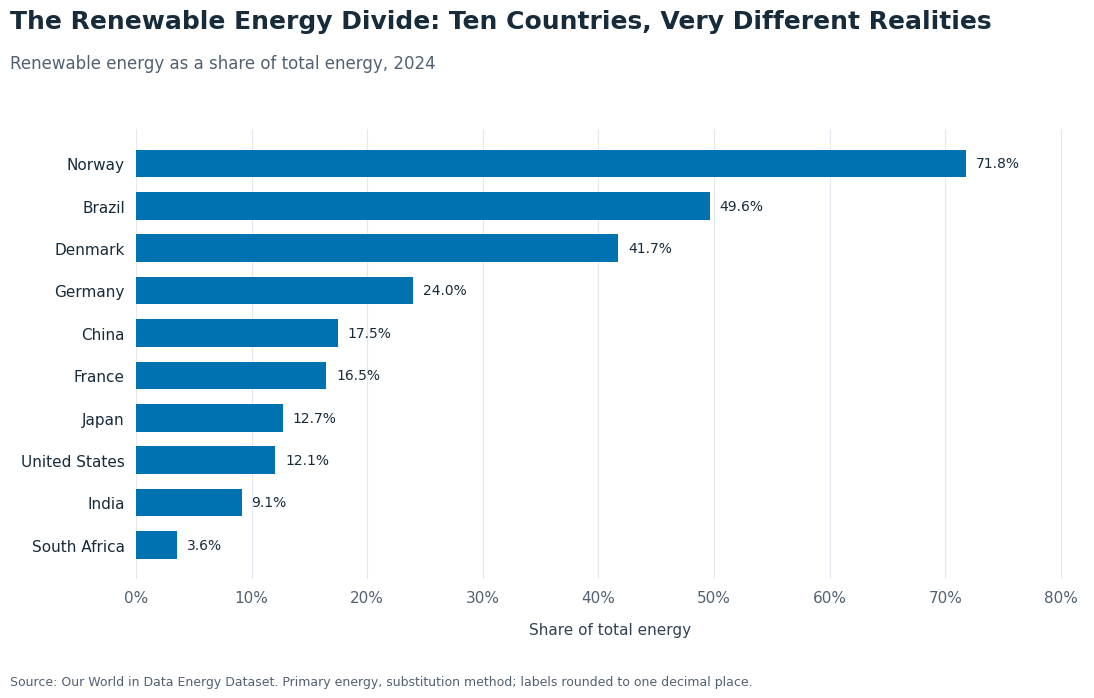

In [2]:
fig, ax = chart_frame(
    "The Renewable Energy Divide: Ten Countries, Very Different Realities",
    "Renewable energy as a share of total energy, 2024",
    "Source: Our World in Data Energy Dataset. Primary energy, substitution method; labels rounded to one decimal place.")
bars = ax.barh(frame["country"], frame["renewables_share_energy"],
               height=0.65, color="#0072B2")
ax.invert_yaxis()
ax.set_xlim(0, 82)
ax.set_xlabel("Share of total energy", labelpad=12)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in frame["renewables_share_energy"]],
             padding=7, fontsize=10, color="#172B3A")
fig.savefig(OUTPUT / "01_renewable_adoption_2024.png", dpi=300, facecolor="white")
plt.show()

**Interpretation.** Norway has the highest renewable share of total energy (71.8%), followed by Brazil (49.6%) and Denmark (41.7%). South Africa has the lowest share (3.6%). The gap between Norway and South Africa is 68.3 percentage points, calculated from unrounded values. The top three all exceed 40%, while each of the other seven remains below 25%. These differences describe the 2024 energy mix; this snapshot alone does not explain their causes.

## Visual 2 - Different Renewable Electricity Pathways
The same country order links this comparison to Visual 1. Stacked horizontal bars show both the combined contribution of three selected sources and the composition of that contribution. A common 0-100% scale represents total electricity generation; the unfilled portion is not classified here. The palette uses distinct blue, orange, and green hues.

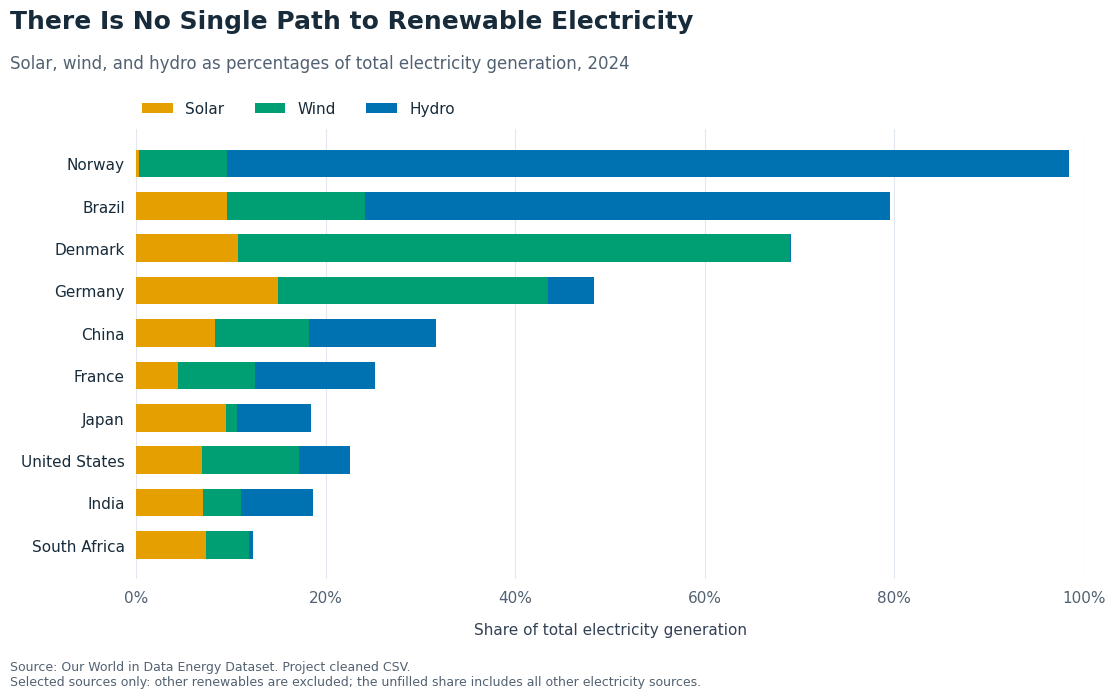

In [3]:
fig, ax = chart_frame(
    "There Is No Single Path to Renewable Electricity",
    "Solar, wind, and hydro as percentages of total electricity generation, 2024",
    "Source: Our World in Data Energy Dataset. Project cleaned CSV.\n"
    "Selected sources only: other renewables are excluded; the unfilled share includes all other electricity sources.")
left = pd.Series(0.0, index=frame.index)
for column, label, color in [
    ("solar_share_elec", "Solar", "#E69F00"),
    ("wind_share_elec", "Wind", "#009E73"),
    ("hydro_share_elec", "Hydro", "#0072B2"),
]:
    ax.barh(frame["country"], frame[column], left=left,
            height=0.65, label=label, color=color)
    left = left + frame[column]
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Share of total electricity generation", labelpad=12)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.015), ncol=3,
          frameon=False, borderaxespad=0)
fig.savefig(OUTPUT / "02_renewable_electricity_pathways_2024.png", dpi=300, facecolor="white")
plt.show()

**Interpretation and chart choice.** Hydropower supplies 88.8% of Norway's electricity and 55.4% of Brazil's, while wind supplies 58.2% of Denmark's. Germany combines substantial wind (28.5%) and solar (14.9%) shares. These contrasts show different electricity mixes, rather than a single common pathway.

Stacking supports comparison of the three sources' combined shares and their composition. Hydro and wind segments do not all share a baseline, so precise individual comparisons are harder than in separate bar charts. Solar, wind, and hydro do **not** represent all renewable electricity; for example, bioenergy is excluded. This single-year chart does not establish historical transitions.

## Improvements for the final presentation
- Give each chart its own slide and check label and source-note readability at the projected size; keep the denominator explanation visible.
- Use the 68.3 percentage-point adoption gap and the hydro-versus-wind contrast as the spoken takeaways. Describe these as 2024 mixes, not evidence of the speed or causes of transition.
- Keep the country order consistent. If individual electricity-source comparisons become the main question, consider separate aligned bar charts; the current stack prioritizes composition.
- Connect these drafts to the planned GDP and historical visuals only after matching years and checking missing values. These are Milestone 3 drafts for the proposed insights.

## Team Contributions
- **GDP visual - [Team member name]:** Add a comparison of GDP and renewable adoption, documenting the GDP year and any missing values. GDP is missing for 2024 in this CSV, so a different complete year or documented source will be needed.
- **Historical-transition visual - [Team member name]:** Add a time-series view of renewable adoption, documenting the period, country selection, and missing-data treatment.